# Table of Contents
- 1. Extracting Temporal Components (Day, Month, Quarter)
- 2. Elapsed Time and Delta Features
- 3. Cyclical Encoding (Sine/Cosine Transforms for Hours/Months)
- 4. Holiday and Business Day Flags

In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for date-time and cyclical feature engineering loaded successfully.")

Global libraries for date-time and cyclical feature engineering loaded successfully.


---
## 1. Extracting Temporal Components (Day, Month, Quarter)

### 1. Definition
Extracting temporal components decomposes datetime timestamps into discrete calendar attributes (such as year, month, day, day of week, and quarter) to expose seasonal and cyclical trends to machine learning models.

###  Naive Example
Extracting the month from e-commerce transaction timestamps to capture Q4 holiday shopping surges.

###  Uses
- Capturing calendar seasonality in sales forecasting and demand planning.
- Grouping high-frequency time-series data into monthly or weekly aggregates.
- Enhancing tree-based model split decisions with temporal context.

In [2]:
df_time = pd.DataFrame({'timestamp': pd.to_datetime(['2026-01-15', '2026-05-20', '2026-09-10', '2026-11-25'])})
df_time['month'] = df_time['timestamp'].dt.month
df_time['quarter'] = df_time['timestamp'].dt.quarter
print("Extracted Temporal Components:\n", df_time)

Extracted Temporal Components:
    timestamp  month  quarter
0 2026-01-15      1        1
1 2026-05-20      5        2
2 2026-09-10      9        3
3 2026-11-25     11        4


## 2. Elapsed Time and Delta Features

### 1. Definition
Elapsed time and delta features calculate the numerical duration between a specific event timestamp and a reference epoch or prior milestone (e.g., account age, days since last purchase).

###  Naive Example
Calculating the number of days since a customer's last support ticket to feed into a customer churn prediction model.

###  Uses
- Measuring customer tenure and recency in retention modeling.
- Tracking equipment wear-and-tear duration in predictive maintenance.
- Quantifying time lags between sequential user actions.

In [3]:
reference_date = pd.to_datetime('2026-10-01')
df_delta = pd.DataFrame({
    'user_id': [1, 2, 3],
    'signup_date': pd.to_datetime(['2026-01-01', '2026-06-01', '2026-09-15'])
})
df_delta['tenure_days'] = (reference_date - df_delta['signup_date']).dt.days
print("Calculated Tenure Delta Features:\n", df_delta)

Calculated Tenure Delta Features:
    user_id signup_date  tenure_days
0        1  2026-01-01          273
1        2  2026-06-01          122
2        3  2026-09-15           16


## 3. Cyclical Encoding (Sine/Cosine Transforms for Hours/Months)

### 1. Definition
Cyclical encoding maps periodic time features (such as hours of the day or months of the year) onto 2D Cartesian coordinates using sine and cosine transformations, preserving smooth continuity across period boundaries (e.g., hour 23 to hour 0).

### 2. Math Formula
For cyclical feature value $v$ with maximum period boundary $max\_val$, sine and cosine features are computed as:
$$x_{sin} = \sin\left(\frac{2\pi \cdot v}{max\_val}\right), \quad x_{cos} = \cos\left(\frac{2\pi \cdot v}{max\_val}\right)$$

### 3. Notation Pronunciation
- $x_{sin}$: "Sine cyclical coordinate projection"
- $x_{cos}$: "Cosine cyclical coordinate projection"
- $max\_val$: "Maximum period cycle value (e.g., 24 for hours)"

### 4. Naive Example
Encoding the hour of day ($23:00$ and $00:00$) so that machine learning algorithms recognize them as adjacent hours rather than numerical extremes ($0$ vs $23$).

### 5. Uses
- Time-series forecasting for hourly traffic, weather, and energy consumption.
- Periodic sensor data analysis and cyclical pattern recognition in neural networks.

Cyclical Sine/Cosine Encoded Hours:
    hour  hour_sin  hour_cos
0     0     0.000     1.000
1     6     1.000     0.000
2    12     0.000    -1.000
3    18    -1.000    -0.000
4    23    -0.259     0.966


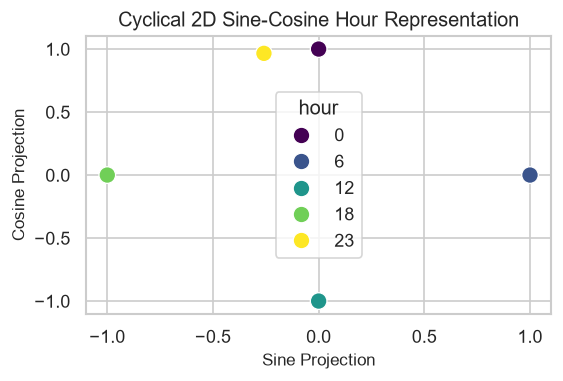

In [5]:
hours = np.array([0, 6, 12, 18, 23])
df_cyc = pd.DataFrame({
    'hour': hours,
    'hour_sin': np.sin(2 * np.pi * hours / 24),
    'hour_cos': np.cos(2 * np.pi * hours / 24)
})
print("Cyclical Sine/Cosine Encoded Hours:\n", df_cyc.round(3))

# Visualization
plt.figure(figsize=(5, 3))
sns.scatterplot(x='hour_sin', y='hour_cos', hue='hour', data=df_cyc, palette='viridis', s=100)
plt.title('Cyclical 2D Sine-Cosine Hour Representation')
plt.xlabel('Sine Projection')
plt.ylabel('Cosine Projection')
plt.show()

---
## 4. Holiday and Business Day Flags

### 1. Definition
Holiday and business day flags are binary indicator variables ($\mathbb{I} \in \{0, 1\}$) that signal whether a given date falls on a weekend, public holiday, or standard business operating day.


The Full Integer Mapping [ df_biz['date'].dt.dayofweek ]

• 0 = Monday
• 1 = Tuesday
• 2 = Wednesday
• 3 = Thursday
• 4 = Friday
• 5 = Saturday
• 6 = Sunday


In [6]:
dates = pd.date_range(start='2026-10-01', periods=5, freq='D')
df_biz = pd.DataFrame({'date': dates})
df_biz['is_weekend'] = df_biz['date'].dt.dayofweek >= 5
df_biz['is_business_day'] = ~df_biz['is_weekend']
print(
    "Business Day Audit Flag DataFrame:\n",
    df_biz,
)

Business Day Audit Flag DataFrame:
         date  is_weekend  is_business_day
0 2026-10-01       False             True
1 2026-10-02       False             True
2 2026-10-03        True            False
3 2026-10-04        True            False
4 2026-10-05       False             True


---
## Summary Table

| Temporal Feature Technique | Core Mechanism | Mathematical / Transform Type | Primary Analytical Purpose |
| :--- | :--- | :--- | :--- |
| **Temporal Component Extraction** | Calendar attribute decomposition | Integer mapping (Month, Day, Quarter) | Capturing calendar seasonality and time-based grouping |
| **Elapsed Time & Deltas** | Date subtraction ($t_{event} - t_{ref}$) | Continuous duration values ($\Delta t$) | Measuring customer tenure, account age, and recency |
| **Cyclical Encoding** | Sine & Cosine trigonometric mapping | 2D Cartesian coordinates ($sin, cos$) | Preserving continuity across period boundaries (hours, months) |
| **Holiday & Business Day Flags** | Binary indicator lookup ($\mathbb{I} \in \{0,1\}$) | Boolean status mapping | Modeling retail demand spikes, weekends, and operating days |